In [2]:
# -------------------------------
# PHASE 1 & 2 : Nettoyage + Exploration
# -------------------------------

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Chargement du fichier (gzip directement lisible)
df = pd.read_csv(
    r"D:\Program Files\projet data analyst imobili\delinquance_commune.csv.gz",
    compression='gzip', sep=';', low_memory=False
)

print("✅ Fichier chargé avec succès !")
print("Dimensions :", df.shape)
print("\nAperçu des colonnes :")
print(df.columns.tolist()[:10])

# === 2. Standardisation des noms de colonnes
df.columns = df.columns.str.lower().str.strip()

# === 3. Aperçu des premières lignes
df.head(5)


✅ Fichier chargé avec succès !
Dimensions : (4714200, 13)

Aperçu des colonnes :
['CODGEO_2025', 'annee', 'indicateur', 'unite_de_compte', 'nombre', 'taux_pour_mille', 'est_diffuse', 'insee_pop', 'insee_pop_millesime', 'insee_log']


,codgeo_2025,annee,indicateur,unite_de_compte,nombre,taux_pour_mille,est_diffuse,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime,complement_info_nombre,complement_info_taux
0,01001,2016,Violences physiques intrafamiliales,Victime,0.0,"0,0000000",diff,767,2016,348,2016,NaN,NaN
1,01001,2016,Violences physiques hors cadre familial,Victime,NaN,NaN,ndiff,767,2016,348,2016,"1,3620690","0,9598386"
2,01001,2016,Violences sexuelles,Victime,0.0,"0,0000000",diff,767,2016,348,2016,NaN,NaN
3,01001,2016,Vols avec armes,Infraction,0.0,"0,0000000",diff,767,2016,348,2016,NaN,NaN
4,01001,2016,Vols violents sans arme,Infraction,0.0,"0,0000000",diff,767,2016,348,2016,NaN,NaN


In [3]:
# Vérifier les valeurs manquantes
missing = df.isna().sum().sort_values(ascending=False)
print("Valeurs manquantes (top 10):\n", missing.head(10))

# Supprimer les lignes sans code géographique
df = df.dropna(subset=['codgeo_2025'])

# Vérifier les types de données
df.info()


Valeurs manquantes (top 10):
 complement_info_nombre    2539786
complement_info_taux      2539786
taux_pour_mille           2175177
nombre                    2174414
codgeo_2025                     0
unite_de_compte                 0
indicateur                      0
annee                           0
est_diffuse                     0
insee_pop_millesime             0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4714200 entries, 0 to 4714199
Data columns (total 13 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   codgeo_2025             object 
 1   annee                   int64  
 2   indicateur              object 
 3   unite_de_compte         object 
 4   nombre                  float64
 5   taux_pour_mille         object 
 6   est_diffuse             object 
 7   insee_pop               int64  
 8   insee_pop_millesime     int64  
 9   insee_log               int64  
 10  insee_log_millesime     int64  
 11  complement_info_no

In [4]:
# Convertir 'annee' en entier
df['annee'] = df['annee'].astype(int)

# Garder uniquement la dernière année
last_year = df['annee'].max()
df = df[df['annee'] == last_year]
print(f"📅 Année la plus récente retenue : {last_year}")


📅 Année la plus récente retenue : 2024


In [5]:
# Vérifier la colonne de comptage
print("Exemples d'indicateurs :", df['indicateur'].unique()[:10])

# Agréger le total des infractions par commune
agg_df = (
    df.groupby('codgeo_2025')
      .agg({'nombre': 'sum'})
      .reset_index()
)

agg_df.rename(columns={'nombre': 'total_faits'}, inplace=True)
print("✅ Agrégation terminée !")
agg_df.head()


Exemples d'indicateurs : ['Violences physiques intrafamiliales'
 'Violences physiques hors cadre familial' 'Violences sexuelles'
 'Vols avec armes' 'Vols violents sans arme'
 'Vols sans violence contre des personnes' 'Cambriolages de logement'
 'Vols de véhicule' 'Vols dans les véhicules'
 "Vols d'accessoires sur véhicules"]
✅ Agrégation terminée !


,codgeo_2025,total_faits
0,01001,0.0
1,01002,0.0
2,01004,859.0
3,01005,30.0
4,01006,0.0


In [6]:
agg_df['score_securite'] = 1 - (agg_df['total_faits'] / agg_df['total_faits'].max())
agg_df.head()


,codgeo_2025,total_faits,score_securite
0,01001,0.0,1.000000
1,01002,0.0,1.000000
2,01004,859.0,0.996689
3,01005,30.0,0.999884
4,01006,0.0,1.000000


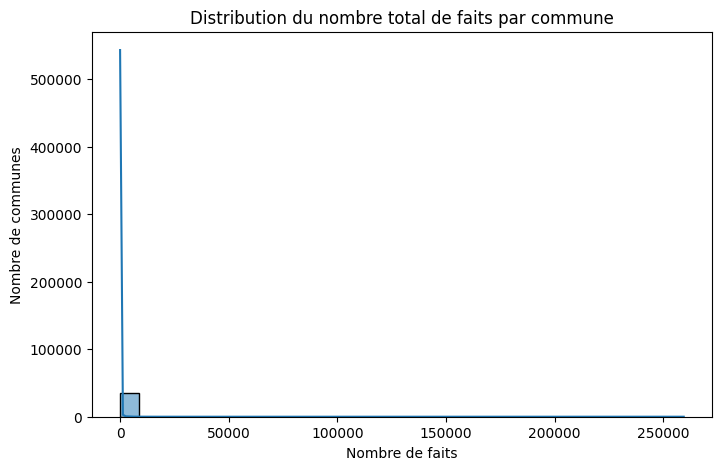

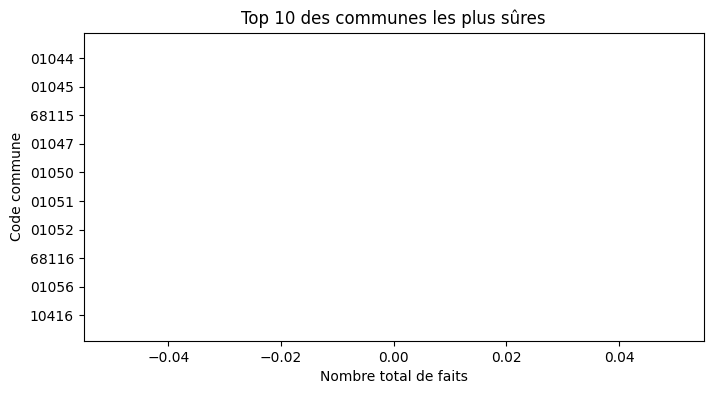

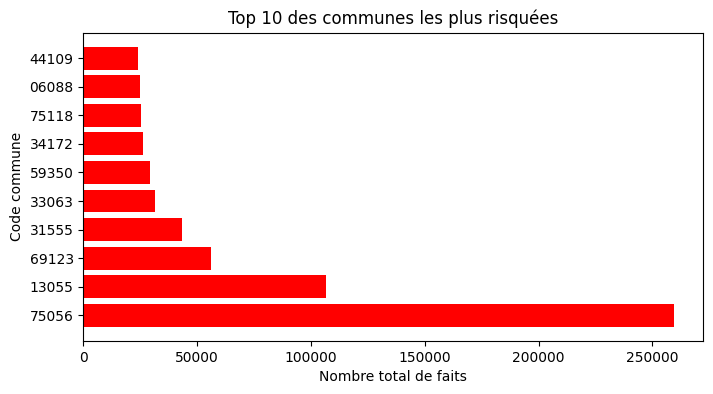

In [7]:
# Distribution générale
plt.figure(figsize=(8,5))
sns.histplot(agg_df['total_faits'], bins=30, kde=True)
plt.title("Distribution du nombre total de faits par commune")
plt.xlabel("Nombre de faits")
plt.ylabel("Nombre de communes")
plt.show()

# Top 10 des communes les plus sûres
top_safe = agg_df.sort_values('total_faits').head(10)
plt.figure(figsize=(8,4))
plt.barh(top_safe['codgeo_2025'], top_safe['total_faits'])
plt.title("Top 10 des communes les plus sûres")
plt.xlabel("Nombre total de faits")
plt.ylabel("Code commune")
plt.show()

# Top 10 des communes les plus risquées
top_risk = agg_df.sort_values('total_faits', ascending=False).head(10)
plt.figure(figsize=(8,4))
plt.barh(top_risk['codgeo_2025'], top_risk['total_faits'], color='red')
plt.title("Top 10 des communes les plus risquées")
plt.xlabel("Nombre total de faits")
plt.ylabel("Code commune")
plt.show()


In [8]:
agg_df.to_csv(
    r"D:\Program Files\projet data analyst imobili\delinquance_clean.csv",
    index=False
)
print("💾 Fichier nettoyé sauvegardé sous : delinquance_clean.csv")


💾 Fichier nettoyé sauvegardé sous : delinquance_clean.csv


In [10]:
# -------------------------------
# PHASE 2 : Calcul du score de sécurité
# -------------------------------

# 1️⃣ On garde uniquement les lignes avec un nombre valide
df_valid = df.dropna(subset=["nombre"])

# 2️⃣ Agrégation par commune (somme des faits constatés)
agg = df_valid.groupby("codgeo_2025", as_index=False)["nombre"].sum()
agg = agg.rename(columns={"nombre": "total_faits"})

# 3️⃣ Normalisation : transformation du total en un score entre 0 et 1
# (1 = très sûre, 0 = la moins sûre)
agg["score_securite"] = 1 - (agg["total_faits"] / agg["total_faits"].max())

# 4️⃣ Arrondir pour lisibilité
agg["score_securite"] = agg["score_securite"].round(3)

# 5️⃣ Afficher un aperçu
print("✅ Score de sécurité calculé !")
print(agg.head())

# 6️⃣ Sauvegarder la version enrichie
agg.to_csv("delinquance_score.csv", index=False)
print("\n📁 Fichier enregistré sous : delinquance_score.csv")


✅ Score de sécurité calculé !
  codgeo_2025  total_faits  score_securite
0       01001          0.0           1.000
1       01002          0.0           1.000
2       01004        859.0           0.997
3       01005         30.0           1.000
4       01006          0.0           1.000

📁 Fichier enregistré sous : delinquance_score.csv
